In [1]:
%run setup.py

## Index

- [STI spreading on network](#sti-spreading)
- [Epidemic modelling](#epidemic-modelling)
  - [SI simulation](#si-simulation)
  - [Infected aggregated by risk category — SI](#si-risk)
  - [SIS simulation](#sis-simulation)
  - [Infected aggregated by risk category — SIS](#sis-risk)
- [STIS model](#stis-model)
  - [SITS simulation](#sits-simulation)
  - [Infected aggregated by risk category — SITS](#sits-risk)
  - [STIS(λ_h): max infected vs. transmission rate](#stis-lambda)
  - [STIS(p): max infected vs. testing probability](#stis-p)
  - [STIS(T_t): max infected vs. testing time](#stis-tt)

<a id="sti-spreading"></a>
# STI spreading on network


In [3]:
import os, glob, re

# Load node metadata: id (col 1) and gender (col 2)
nodes_df = pd.read_csv('ensembles/G_nodes.csv', header=0, index_col=0)
nodes_df.columns = ['id', 'gender'] + list(nodes_df.columns[2:])
node_gender = dict(zip(nodes_df['id'], nodes_df['gender']))

# Load all snapshots from ensembles/G_y.m.csv
edges_by_snapshot = {}   # (year, month) -> list of (source, target, weight)
all_nodes_set = set()

pattern = re.compile(r'G_(\d+)\.(\d+)\.csv$')
for fpath in sorted(glob.glob('ensembles/G_*.*.csv')):
    m = pattern.search(os.path.basename(fpath))
    if not m:
        continue
    year, month = int(m.group(1)), int(m.group(2))
    df_snap = pd.read_csv(fpath, header=0)
    edges = list(zip(df_snap['source'], df_snap['target'], df_snap['weight']))
    edges_by_snapshot[(year, month)] = edges
    for u, v, _ in edges:
        all_nodes_set.update([u, v])

all_nodes = list(all_nodes_set)
snapshots = sorted(edges_by_snapshot.keys())
print(f"Loaded {len(snapshots)} snapshots, {len(all_nodes)} nodes")


Loaded 72 snapshots, 882 nodes


In [4]:
# Aggregate degree: number of unique neighbours per node across all snapshots
from collections import defaultdict

neighbours = defaultdict(set)
for snap, edges in edges_by_snapshot.items():
    for u, v, w in edges:
        neighbours[u].add(v)
        neighbours[v].add(u)

agg_degree_map = {n: len(nbrs) for n, nbrs in neighbours.items()}
print(f"Mean aggregate degree: {np.mean(list(agg_degree_map.values())):.2f}")


Mean aggregate degree: 1.84


<a id="epidemic-modelling"></a>
# Epidemic modelling


<a id="si-simulation"></a>
## SI simulation


In [5]:
criteria = ['random', 'high_to_hub', 'high_to_low']
si_results = {}

for criterion in criteria:
    beta_map = sim.assign_transmission_rates_generic(agg_degree_map, criterion=criterion)
    counts, snaps = sim.run_SI_simulations_generic(
        edges_by_snapshot, all_nodes, beta_map,
        n_simulations=N_SIMULATIONS, n_seeds=10
    )
    si_results[criterion] = (counts, snaps)

print("SI simulations done")


SI simulations done


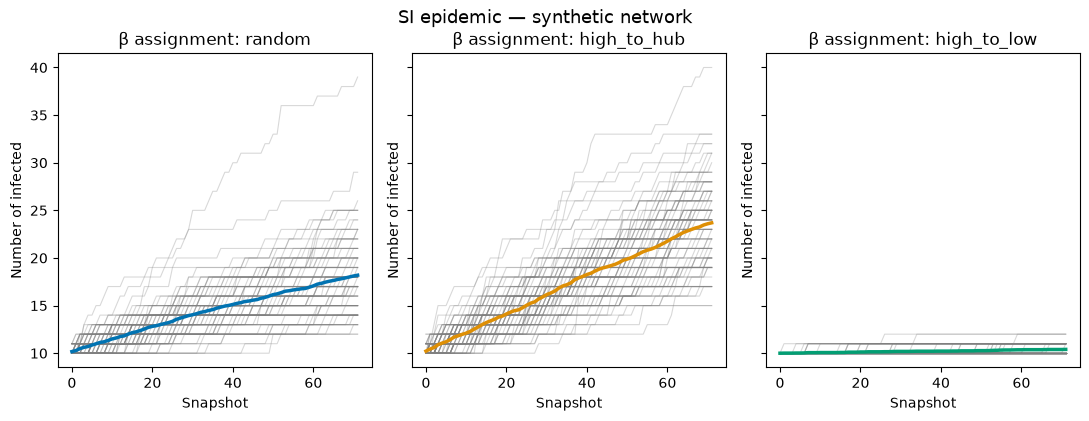

In [6]:
palette = sns.color_palette('colorblind')
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharex=True, sharey=True)

for ax, (criterion, color) in zip(axes, zip(criteria, palette)):
    counts, snaps = si_results[criterion]
    for run in counts:
        ax.plot(range(len(snaps)), run, color='gray', alpha=0.3, linewidth=0.8)
    ax.plot(range(len(snaps)), counts.mean(axis=0), color=color, linewidth=2.5)
    ax.set_title(f'β assignment: {criterion}')
    ax.set_xlabel('Snapshot')
    ax.set_ylabel('Number of infected')
    ax.set_box_aspect(1)

fig.suptitle('SI epidemic — synthetic network', fontsize=13)
plt.tight_layout()
plt.show()


<a id="si-risk"></a>
### Infected aggregated by risk category


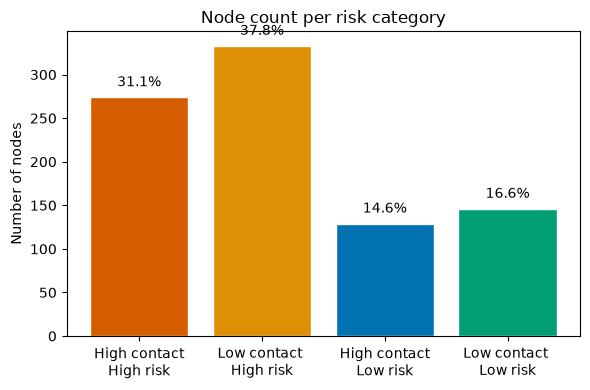

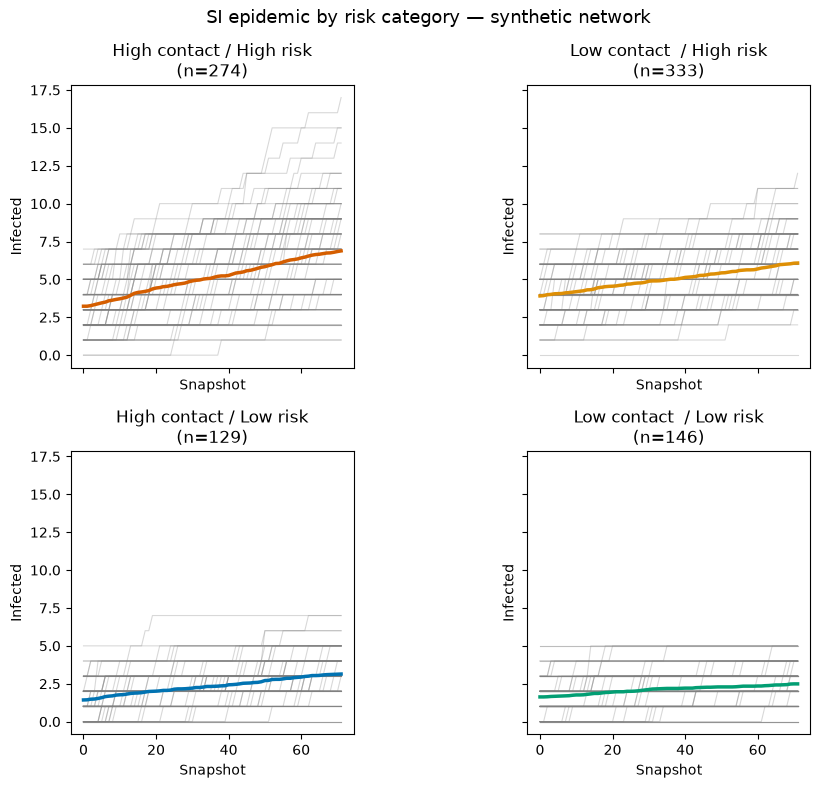

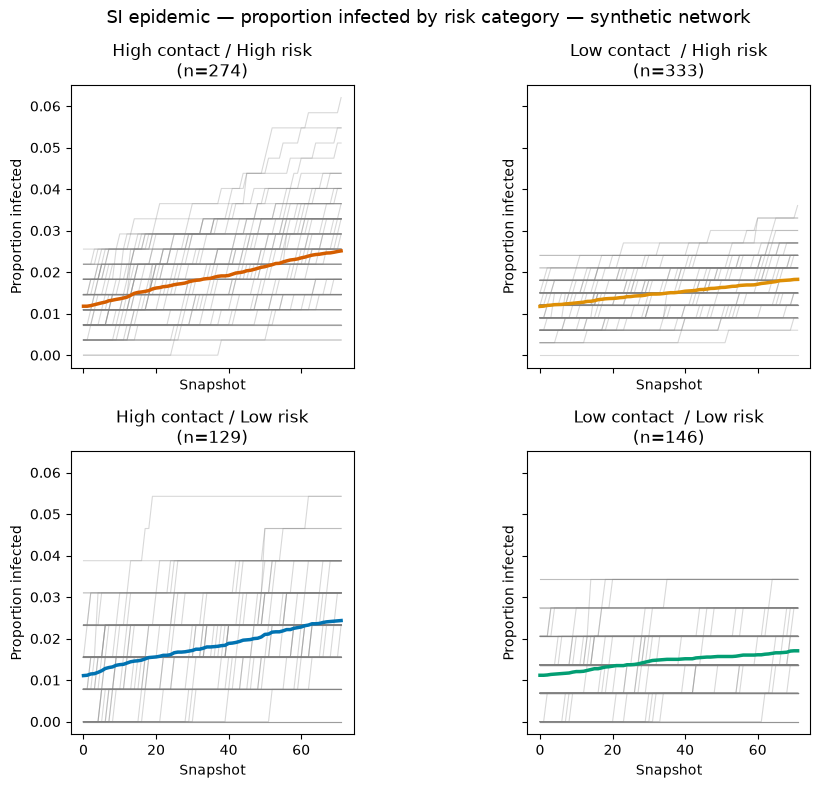

In [7]:
# Risk categories: 4 groups crossing contact activity × beta assignment
# high_contact = aggregate degree > mean
# high_risk    = high beta (beta_high)

mean_degree = np.mean(list(agg_degree_map.values()))

def compute_risk_categories(beta_map):
    beta_high_val  = max(beta_map.values())
    cats = {
        ('high_contact', 'high_risk'): [],   # dark orange
        ('low_contact',  'high_risk'): [],   # light orange
        ('high_contact', 'low_risk'):  [],   # blue
        ('low_contact',  'low_risk'):  [],   # green
    }
    for node, beta in beta_map.items():
        contact = 'high_contact' if agg_degree_map.get(node, 0) > mean_degree else 'low_contact'
        risk    = 'high_risk'    if beta >= beta_high_val                       else 'low_risk'
        cats[(contact, risk)].append(node)
    return cats

def run_SI_by_risk(beta_map, risk_cats, n_simulations=100, n_seeds=10):
    """Track per-category infected counts across snapshots."""
    snaps = sorted(edges_by_snapshot.keys())
    cat_keys = list(risk_cats.keys())
    results  = {k: np.zeros((n_simulations, len(snaps)), dtype=int) for k in cat_keys}

    for sim in range(n_simulations):
        infected = set(np.random.choice(all_nodes, size=n_seeds, replace=False))
        for t, snap in enumerate(snaps):
            new_infected = set()
            for u, v, w in edges_by_snapshot[snap]:
                if u in infected and v not in infected:
                    if np.random.rand() < min(1.0, w * beta_map.get(u, 0.001)):
                        new_infected.add(v)
                if v in infected and u not in infected:
                    if np.random.rand() < min(1.0, w * beta_map.get(v, 0.001)):
                        new_infected.add(u)
            infected |= new_infected
            for k, members in risk_cats.items():
                results[k][sim, t] = len(infected & set(members))
    return results, snaps

# Run with random assignment (matches real-data notebook)
beta_map_random = sim.assign_transmission_rates_generic(agg_degree_map, criterion='random')
risk_cats = compute_risk_categories(beta_map_random)
si_risk_results, snaps = run_SI_by_risk(beta_map_random, risk_cats, n_simulations=N_SIMULATIONS)

_full_pal    = sns.color_palette('colorblind', n_colors=8)
palette_risk = [_full_pal[3], _full_pal[1], _full_pal[0], _full_pal[2]]
cat_labels = {
    ('high_contact', 'high_risk'): 'High contact / High risk',   # dark orange
    ('low_contact',  'high_risk'): 'Low contact  / High risk',   # light orange
    ('high_contact', 'low_risk'):  'High contact / Low risk',    # blue
    ('low_contact',  'low_risk'):  'Low contact  / Low risk',    # green
}

risk_cats_cur = risk_cats
# --- Bar plot: node count per risk category ---
fig, ax = plt.subplots(figsize=(6, 4))
_bar_labels = [cat_labels[c].replace(' / ', '\n') for c in risk_cats_cur.keys()]
_bar_vals   = [len(risk_cats_cur[c]) for c in risk_cats_cur]
_total      = sum(_bar_vals)
_bars = ax.bar(_bar_labels, _bar_vals,
               color=list(palette_risk)[:4], edgecolor='white')
for _bar, _val in zip(_bars, _bar_vals):
    ax.text(_bar.get_x() + _bar.get_width() / 2,
            _bar.get_height() + _total * 0.01,
            f'{_val / _total:.1%}', ha='center', va='bottom', fontsize=10)
ax.set_ylabel('Number of nodes')
ax.set_title('Node count per risk category')
plt.tight_layout()
plt.show()

# --- Plot: number of infected ---
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes_flat = axes.flatten()

for ax, (cat, color) in zip(axes_flat, zip(risk_cats.keys(), palette_risk)):
    counts = si_risk_results[cat]
    n_members = len(risk_cats[cat])
    mean_counts = counts.mean(axis=0)
    for run in counts:
        ax.plot(range(len(snaps)), run, color='gray', alpha=0.3, linewidth=0.8)
    ax.plot(range(len(snaps)), mean_counts, color=color, linewidth=2.5)
    ax.set_title(f'{cat_labels[cat]}\n(n={n_members})')
    ax.set_xlabel('Snapshot')
    ax.set_ylabel('Infected')
    ax.set_box_aspect(1)

fig.suptitle('SI epidemic by risk category — synthetic network', fontsize=13)
plt.tight_layout()
plt.show()

# --- Plot: proportion of infected ---
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes_flat = axes.flatten()

for ax, (cat, color) in zip(axes_flat, zip(risk_cats.keys(), palette_risk)):
    counts = si_risk_results[cat]
    n_members = len(risk_cats[cat])
    for run in counts:
        ax.plot(range(len(snaps)), run / n_members, color='gray', linewidth=0.8, alpha=0.3)
    ax.plot(range(len(snaps)), counts.mean(axis=0) / n_members, color=color, linewidth=2.5)
    ax.set_title(f'{cat_labels[cat]}\n(n={n_members})')
    ax.set_xlabel('Snapshot')
    ax.set_ylabel('Proportion infected')
    ax.set_box_aspect(1)

fig.suptitle('SI epidemic — proportion infected by risk category — synthetic network', fontsize=13)
plt.tight_layout()
plt.show()


<a id="sis-simulation"></a>
## SIS simulation


In [8]:
sis_results = {}

for criterion in criteria:
    beta_map = sim.assign_transmission_rates_generic(agg_degree_map, criterion=criterion)
    counts, snaps = sim.run_SIS_simulations_generic(
        edges_by_snapshot, all_nodes, beta_map,
        n_simulations=N_SIMULATIONS, n_seeds=10, recovery_time_years=1.0
    )
    sis_results[criterion] = (counts, snaps)

print("SIS simulations done")


SIS simulations done


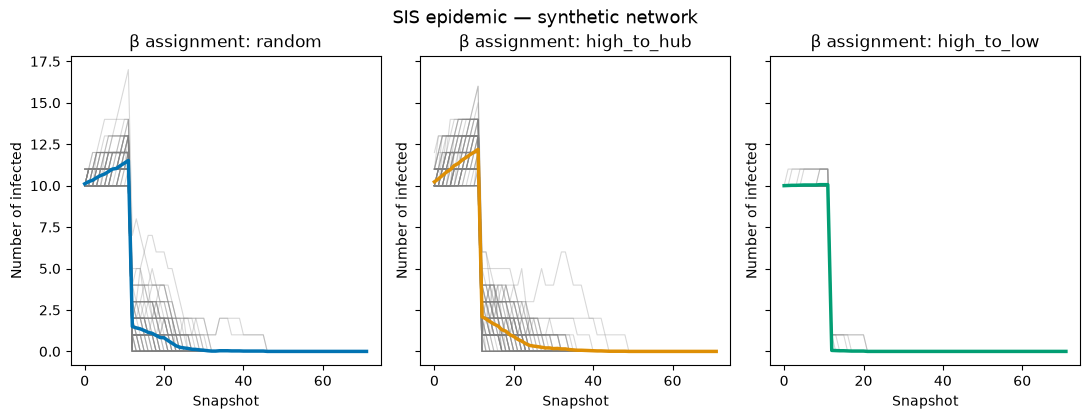

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharex=True, sharey=True)

for ax, (criterion, color) in zip(axes, zip(criteria, palette)):
    counts, snaps = sis_results[criterion]
    for run in counts:
        ax.plot(range(len(snaps)), run, color='gray', alpha=0.3, linewidth=0.8)
    ax.plot(range(len(snaps)), counts.mean(axis=0), color=color, linewidth=2.5)
    ax.set_title(f'β assignment: {criterion}')
    ax.set_xlabel('Snapshot')
    ax.set_ylabel('Number of infected')
    ax.set_box_aspect(1)

fig.suptitle('SIS epidemic — synthetic network', fontsize=13)
plt.savefig('./Images/cool_plot.png')
plt.savefig('./Images/cool_plot.pdf')
plt.savefig('./Images/cool_plot.svg')
plt.tight_layout()
plt.show()


<a id="sis-risk"></a>
### Infected aggregated by risk category


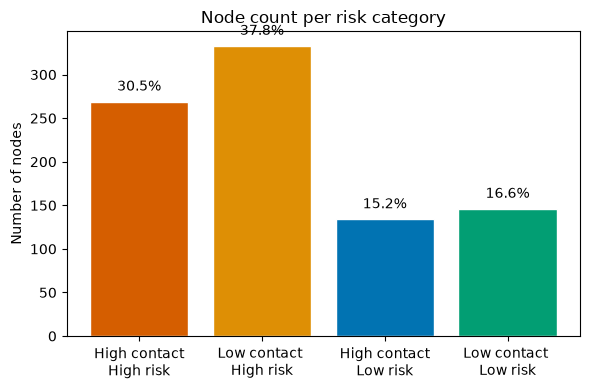

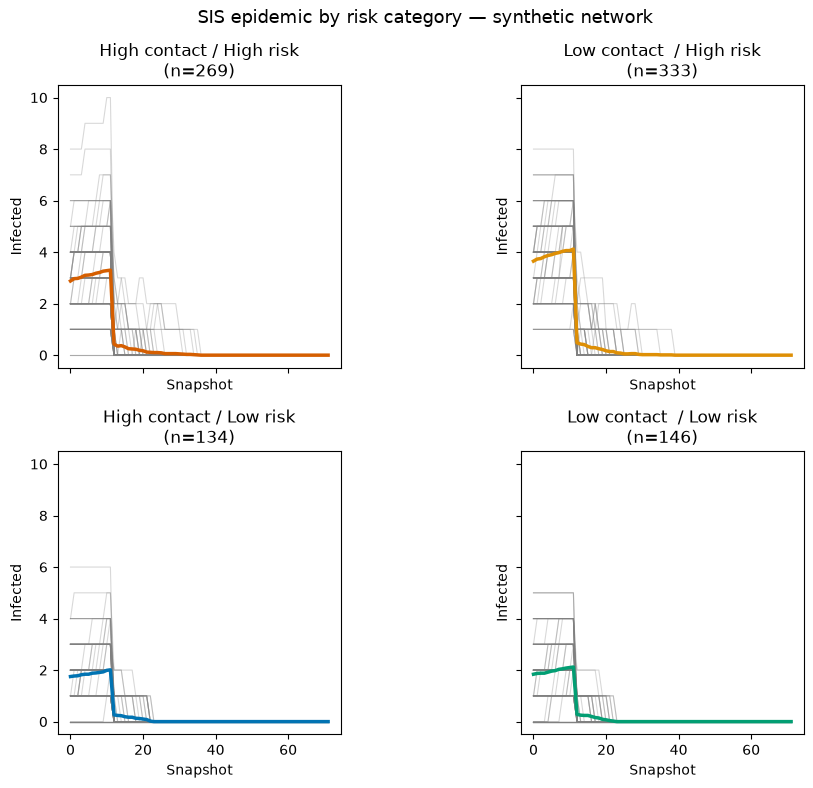

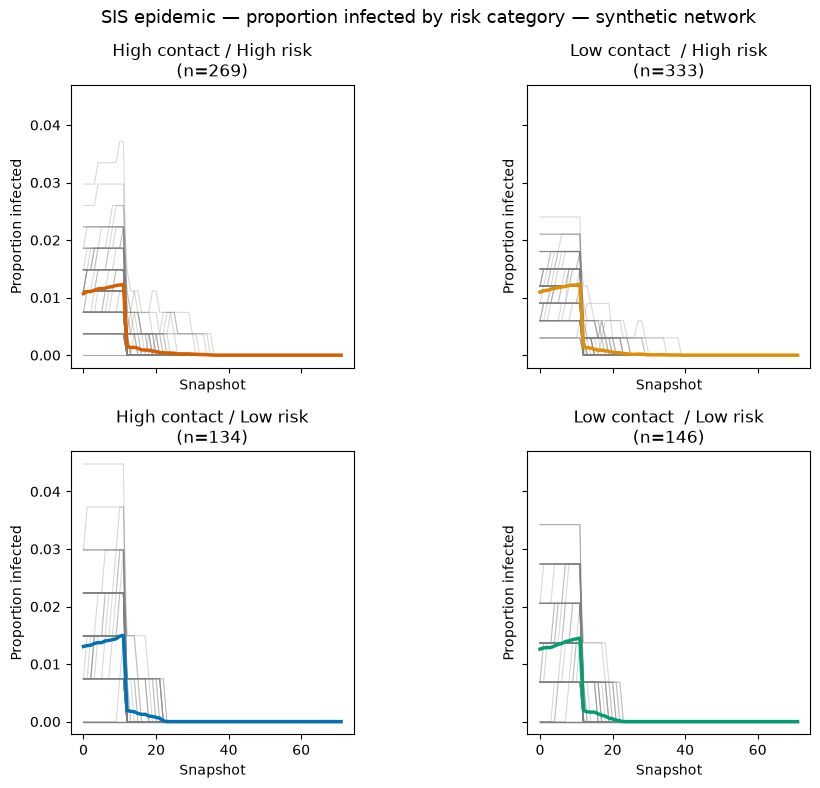

In [10]:
def run_SIS_by_risk(beta_map, risk_cats, n_simulations=N_SIMULATIONS, n_seeds=10, recovery_time_years=1.0):
    snaps = sorted(edges_by_snapshot.keys())
    recovery_snapshots = round(recovery_time_years * 12)
    cat_keys = list(risk_cats.keys())
    results  = {k: np.zeros((n_simulations, len(snaps)), dtype=int) for k in cat_keys}

    for sim in range(n_simulations):
        infection_time = {
            node: 0
            for node in np.random.choice(all_nodes, size=n_seeds, replace=False)
        }
        for t, snap in enumerate(snaps):
            recovered = {node for node, t_inf in infection_time.items()
                         if (t - t_inf) >= recovery_snapshots}
            for node in recovered:
                del infection_time[node]
            infected = set(infection_time.keys())
            new_infected = {}
            for u, v, w in edges_by_snapshot[snap]:
                if u in infected and v not in infected and v not in new_infected:
                    if np.random.rand() < min(1.0, w * beta_map.get(u, 0.001)):
                        new_infected[v] = t
                if v in infected and u not in infected and u not in new_infected:
                    if np.random.rand() < min(1.0, w * beta_map.get(v, 0.001)):
                        new_infected[u] = t
            infection_time.update(new_infected)
            for k, members in risk_cats.items():
                results[k][sim, t] = len(set(infection_time.keys()) & set(members))
    return results, snaps

beta_map_random_sis = sim.assign_transmission_rates_generic(agg_degree_map, criterion='random')
risk_cats_sis = compute_risk_categories(beta_map_random_sis)
sis_risk_results, snaps_sis = run_SIS_by_risk(beta_map_random_sis, risk_cats_sis, n_simulations=N_SIMULATIONS)

risk_cats_cur = risk_cats_sis
# --- Bar plot: node count per risk category ---
fig, ax = plt.subplots(figsize=(6, 4))
_bar_labels = [cat_labels[c].replace(' / ', '\n') for c in risk_cats_cur.keys()]
_bar_vals   = [len(risk_cats_cur[c]) for c in risk_cats_cur]
_total      = sum(_bar_vals)
_bars = ax.bar(_bar_labels, _bar_vals,
               color=list(palette_risk)[:4], edgecolor='white')
for _bar, _val in zip(_bars, _bar_vals):
    ax.text(_bar.get_x() + _bar.get_width() / 2,
            _bar.get_height() + _total * 0.01,
            f'{_val / _total:.1%}', ha='center', va='bottom', fontsize=10)
ax.set_ylabel('Number of nodes')
ax.set_title('Node count per risk category')
plt.tight_layout()
plt.show()

# --- Plot: number of infected ---
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes_flat = axes.flatten()

for ax, (cat, color) in zip(axes_flat, zip(risk_cats_sis.keys(), palette_risk)):
    counts = sis_risk_results[cat]
    n_members = len(risk_cats_sis[cat])
    mean_counts = counts.mean(axis=0)
    for run in counts:
        ax.plot(range(len(snaps_sis)), run, color='gray', alpha=0.3, linewidth=0.8)
    ax.plot(range(len(snaps_sis)), mean_counts, color=color, linewidth=2.5)
    ax.set_title(f'{cat_labels[cat]}\n(n={n_members})')
    ax.set_xlabel('Snapshot')
    ax.set_ylabel('Infected')
    ax.set_box_aspect(1)

fig.suptitle('SIS epidemic by risk category — synthetic network', fontsize=13)
plt.tight_layout()
plt.show()

# --- Plot: proportion of infected ---
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes_flat = axes.flatten()

for ax, (cat, color) in zip(axes_flat, zip(risk_cats_sis.keys(), palette_risk)):
    counts = sis_risk_results[cat]
    n_members = len(risk_cats_sis[cat])
    for run in counts:
        ax.plot(range(len(snaps_sis)), run / n_members, color='gray', linewidth=0.8, alpha=0.3)
    ax.plot(range(len(snaps_sis)), counts.mean(axis=0) / n_members, color=color, linewidth=2.5)
    ax.set_title(f'{cat_labels[cat]}\n(n={n_members})')
    ax.set_xlabel('Snapshot')
    ax.set_ylabel('Proportion infected')
    ax.set_box_aspect(1)

fig.suptitle('SIS epidemic — proportion infected by risk category — synthetic network', fontsize=13)
plt.tight_layout()
plt.show()


### $SIS(\lambda_h)$: maximum number of infected as a funciton of transmission rate

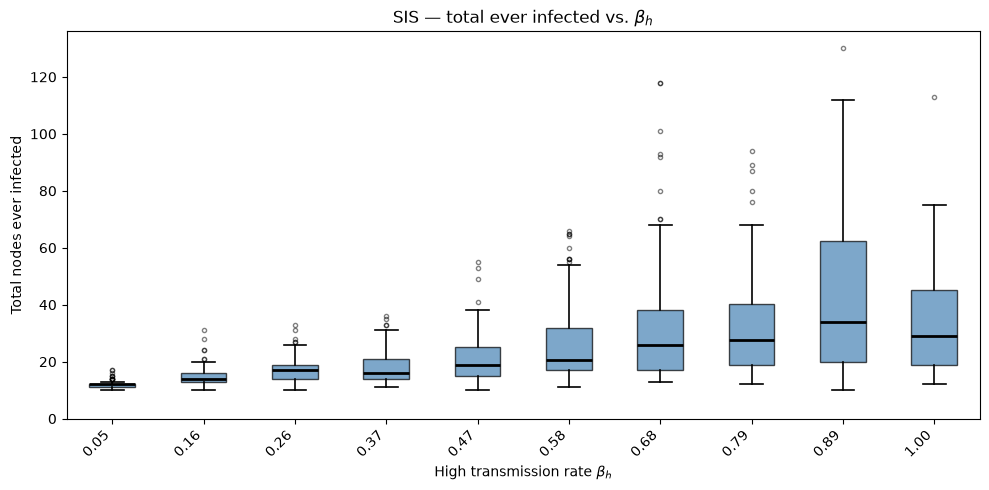

In [11]:
beta_h_sis_values = np.linspace(0.05, 1, 10)
ever_infected_sis_bh = {}

snapshots_sis = sorted(edges_by_snapshot.keys())
recovery_snaps = round(1.0 * 12)

for bh in beta_h_sis_values:
    beta_map_bh = sim.assign_transmission_rates_generic(
        agg_degree_map, criterion='random', beta_high=bh
    )
    ever_per_sim = np.zeros(N_SIMULATIONS, dtype=int)
    for s in range(N_SIMULATIONS):
        infection_time = {node: 0 for node in np.random.choice(all_nodes, size=10, replace=False)}
        ever = set(infection_time)
        for t, snap in enumerate(snapshots_sis):
            for node in [n for n, t0 in list(infection_time.items()) if (t - t0) >= recovery_snaps]:
                del infection_time[node]
            infected = set(infection_time)
            new_inf = {}
            for u, v, w in edges_by_snapshot[snap]:
                if u in infected and v not in infected and v not in new_inf:
                    if np.random.rand() < min(1.0, w * beta_map_bh.get(u, 0.001)):
                        new_inf[v] = t
                if v in infected and u not in infected and u not in new_inf:
                    if np.random.rand() < min(1.0, w * beta_map_bh.get(v, 0.001)):
                        new_inf[u] = t
            infection_time.update(new_inf)
            ever.update(new_inf)
        ever_per_sim[s] = len(ever)
    ever_infected_sis_bh[bh] = ever_per_sim

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    [ever_infected_sis_bh[bh] for bh in beta_h_sis_values],
    label=[f'{bh:.2f}' for bh in beta_h_sis_values],
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', alpha=0.7),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2),
    flierprops=dict(marker='o', markersize=3, alpha=0.5)
)
ax.set_xticklabels([f'{bh:.2f}' for bh in beta_h_sis_values], rotation=45, ha='right')
ax.set_ylim(bottom=0)
ax.set_xlabel(r'High transmission rate $\beta_h$')
ax.set_ylabel('Total nodes ever infected')
ax.set_title(r'SIS — total ever infected vs. $\beta_h$')
plt.tight_layout()
plt.show()


<a id="stis-model"></a>
# STIS model

<a id="sits-simulation"></a>
## SITS simulation


In [12]:
# Run SITS simulations for each assignment criterion
criteria = ['random', 'high_to_hub', 'high_to_low']
sits_results = {}

for criterion in criteria:
    beta_map = sim.assign_transmission_rates_generic(agg_degree_map, criterion=criterion)
    counts, snaps = sim.run_SITS_simulations_generic(
        edges_by_snapshot, all_nodes, beta_map, n_simulations=N_SIMULATIONS
    )
    sits_results[criterion] = counts['I'] + counts['T']   # total infected

print("SITS simulations complete.")


SITS simulations complete.


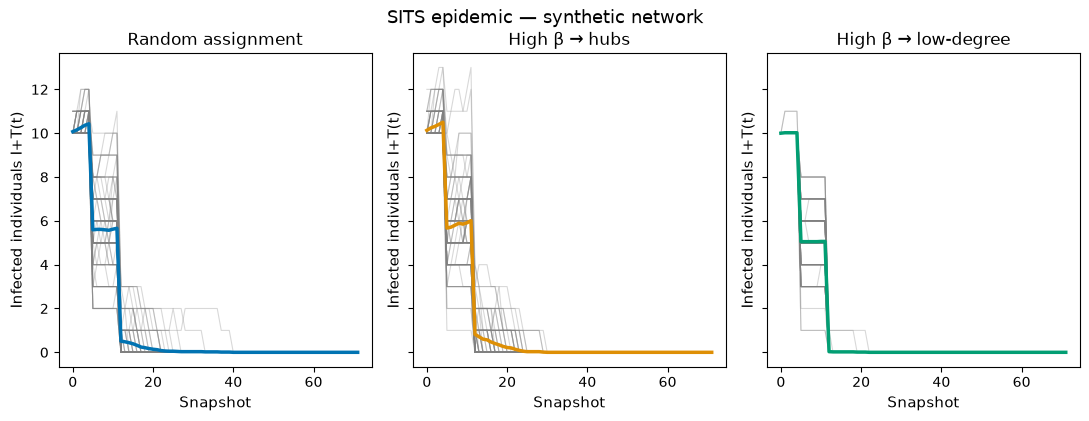

In [13]:
palette = sns.color_palette('colorblind')
titles  = ['Random assignment', 'High β → hubs', 'High β → low-degree']

fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharex=True, sharey=True)

for ax, (criterion, color, title) in zip(axes, zip(criteria, palette, titles)):
    for run in sits_results[criterion]:
        ax.plot(range(len(snaps)), run, color='gray', alpha=0.3, linewidth=0.8)
    ax.plot(range(len(snaps)), sits_results[criterion].mean(axis=0), color=color, linewidth=2.5)
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Snapshot', fontsize=11)
    ax.set_ylabel('Infected individuals I+T(t)', fontsize=11)
    ax.set_box_aspect(1)

fig.suptitle('SITS epidemic — synthetic network', fontsize=13)
plt.tight_layout()
plt.show()


<a id="sits-risk"></a>
### Infected aggregated by risk category


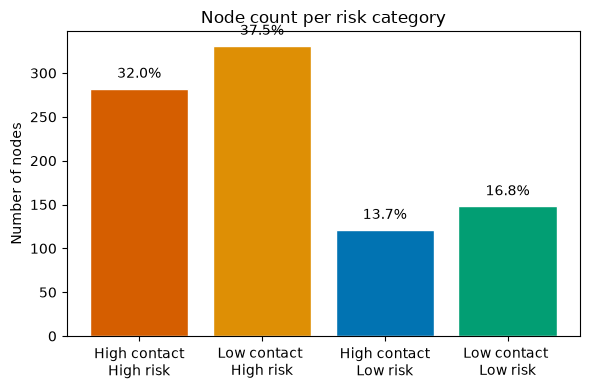

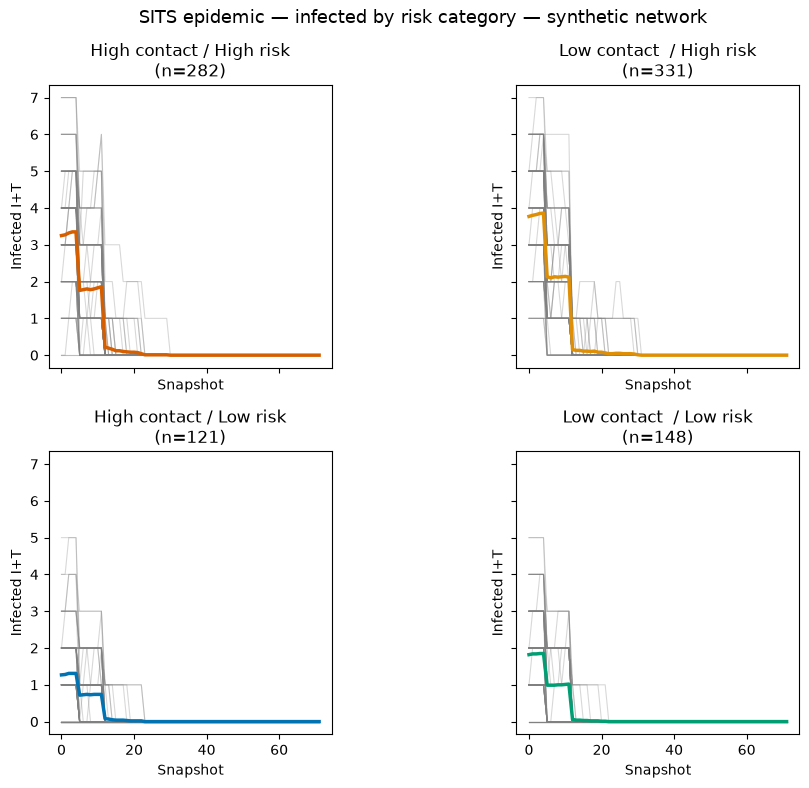

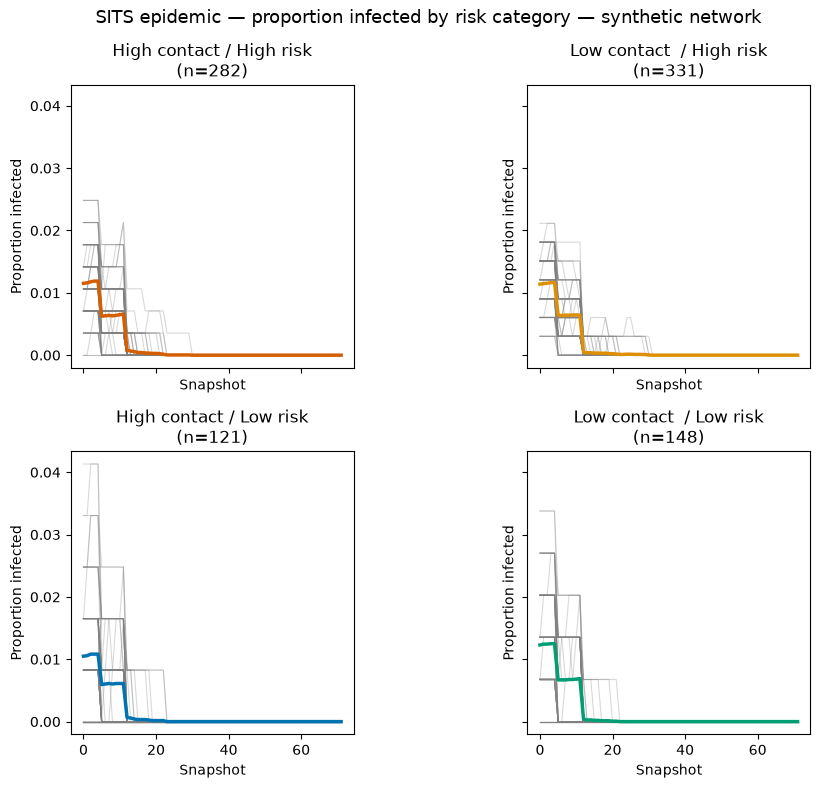

In [14]:
# Reuse risk_cats, cat_labels, palette_risk from SI section above
p_test           = 0.5
beta_tested      = 0.001
recovery_I_snaps = 12   # 1 year
recovery_T_snaps = 5    # 5 months
n_simulations=N_SIMULATIONS

beta_map_sits = sim.assign_transmission_rates_generic(agg_degree_map, criterion='random')
risk_cats_sits = compute_risk_categories(beta_map_sits)

sits_risk_results = {cat: np.zeros((n_simulations, len(snaps)), dtype=int)
                     for cat in risk_cats_sits}

for simul in range(n_simulations):
    time_I       = {}
    time_T       = {}
    pending_test = {}
    beta_current = dict(beta_map_sits)

    for node in np.random.choice(all_nodes, size=10, replace=False):
        time_I[node]       = 0
        pending_test[node] = 0

    for t, snap in enumerate(snaps):
        # Recovery
        for node in [n for n, t0 in list(time_I.items()) if (t - t0) >= recovery_I_snaps]:
            del time_I[node]
            beta_current[node] = beta_map_sits[node]
        for node in [n for n, t0 in list(time_T.items()) if (t - t0) >= recovery_T_snaps]:
            del time_T[node]
            beta_current[node] = beta_map_sits[node]
        # Testing
        for node in list(pending_test):
            if node in time_I:
                if np.random.rand() < p_test:
                    time_T[node] = t
                    del time_I[node]
                    beta_current[node] = beta_tested
        pending_test.clear()
        # Transmission
        infected_all = set(time_I) | set(time_T)
        new_infected = {}
        for u, v, w in edges_by_snapshot[snap]:
            if u in infected_all and v not in infected_all and v not in new_infected:
                if np.random.rand() < min(1.0, w * beta_current.get(u, 0.001)):
                    new_infected[v] = t
            if v in infected_all and u not in infected_all and u not in new_infected:
                if np.random.rand() < min(1.0, w * beta_current.get(v, 0.001)):
                    new_infected[u] = t
        for node, t0 in new_infected.items():
            time_I[node]       = t0
            pending_test[node] = t0
        infected_all = set(time_I) | set(time_T)
        for cat, members in risk_cats_sits.items():
            sits_risk_results[cat][simul, t] = len(infected_all & set(members))

risk_cats_cur = risk_cats_sits
# --- Bar plot: node count per risk category ---
fig, ax = plt.subplots(figsize=(6, 4))
_bar_labels = [cat_labels[c].replace(' / ', '\n') for c in risk_cats_cur.keys()]
_bar_vals   = [len(risk_cats_cur[c]) for c in risk_cats_cur]
_total      = sum(_bar_vals)
_bars = ax.bar(_bar_labels, _bar_vals,
               color=list(palette_risk)[:4], edgecolor='white')
for _bar, _val in zip(_bars, _bar_vals):
    ax.text(_bar.get_x() + _bar.get_width() / 2,
            _bar.get_height() + _total * 0.01,
            f'{_val / _total:.1%}', ha='center', va='bottom', fontsize=10)
ax.set_ylabel('Number of nodes')
ax.set_title('Node count per risk category')
plt.tight_layout()
plt.show()

# --- Plot: number of infected ---
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes_flat = axes.flatten()

for ax, (cat, color) in zip(axes_flat, zip(risk_cats_sits.keys(), palette_risk)):
    counts   = sits_risk_results[cat]
    n_members = len(risk_cats_sits[cat])
    mean_counts = counts.mean(axis=0)
    for run in counts:
        ax.plot(range(len(snaps)), run, color='gray', alpha=0.3, linewidth=0.8)
    ax.plot(range(len(snaps)), mean_counts, color=color, linewidth=2.5)
    ax.set_title(f'{cat_labels[cat]}\n(n={n_members})')
    ax.set_xlabel('Snapshot')
    ax.set_ylabel('Infected I+T')
    ax.set_box_aspect(1)

fig.suptitle('SITS epidemic — infected by risk category — synthetic network', fontsize=13)
plt.tight_layout()
plt.show()

# --- Plot: proportion of infected ---
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
axes_flat = axes.flatten()

for ax, (cat, color) in zip(axes_flat, zip(risk_cats_sits.keys(), palette_risk)):
    counts    = sits_risk_results[cat]
    n_members = len(risk_cats_sits[cat])
    for run in counts:
        ax.plot(range(len(snaps)), run / n_members, color='gray', alpha=0.3, linewidth=0.8)
    ax.plot(range(len(snaps)), counts.mean(axis=0) / n_members, color=color, linewidth=2.5)
    ax.set_title(f'{cat_labels[cat]}\n(n={n_members})')
    ax.set_xlabel('Snapshot')
    ax.set_ylabel('Proportion infected')
    ax.set_box_aspect(1)

fig.suptitle('SITS epidemic — proportion infected by risk category — synthetic network', fontsize=13)
plt.tight_layout()
plt.show()

<a id="stis-lambda"></a>
## $STIS(\lambda_h)$: maximum number of infected as a funciton of transmission rate

In [15]:
# Run SITS for three representative beta_high values
beta_h_plot_values = [0.05, 0.5, 1.0]
sits_bh_results = {}

for bh in beta_h_plot_values:
    beta_map_bh = sim.assign_transmission_rates_generic(
        agg_degree_map, criterion='random', beta_high=bh
    )
    counts, snaps = sim.run_SITS_simulations_generic(
        edges_by_snapshot, all_nodes, beta_map_bh,
        n_simulations=N_SIMULATIONS, n_seeds=10
    )
    sits_bh_results[bh] = (counts, snaps)


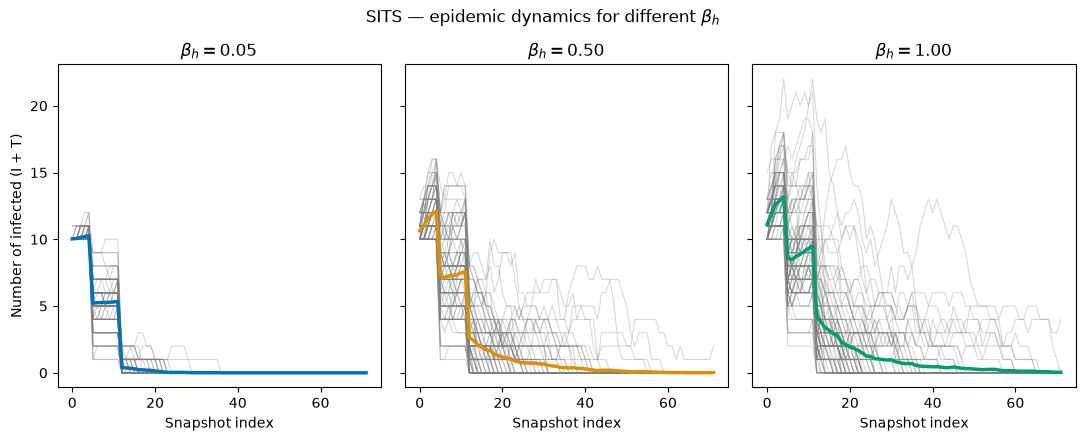

In [16]:
pal = sns.color_palette('colorblind', 6)
bh_colors = {0.05: pal[0], 0.5: pal[1], 1.0: pal[2]}
bh_labels = {0.05: r'$\beta_h = 0.05$', 0.5: r'$\beta_h = 0.50$', 1.0: r'$\beta_h = 1.00$'}

fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharex=True, sharey=True)

for ax, bh in zip(axes, beta_h_plot_values):
    counts, snaps = sits_bh_results[bh]
    x = np.arange(len(snaps))   # snaps are (year, month) tuples
    total = counts['I'] + counts['T']
    for traj in total:
        ax.plot(x, traj, color='gray', linewidth=0.8, alpha=0.3)
    ax.plot(x, total.mean(axis=0), color=bh_colors[bh], linewidth=2.5, label=bh_labels[bh])
    ax.set_title(bh_labels[bh])
    ax.set_xlabel('Snapshot index')
    ax.set_box_aspect(1)

axes[0].set_ylabel('Number of infected (I + T)')
fig.suptitle(r'SITS — epidemic dynamics for different $\beta_h$', y=1.02)
fig.tight_layout()
plt.show()


In [17]:
beta_high_values = np.linspace(0.05, 1, 10)
ever_infected_beta_h = {}

for bh in beta_high_values:
    beta_map_bh = sim.assign_transmission_rates_generic(
        agg_degree_map, criterion='random', beta_high=bh
    )
    counts, _ = sim.run_SITS_simulations_generic(
        edges_by_snapshot, all_nodes, beta_map_bh,
        n_simulations=N_SIMULATIONS, n_seeds=10
    )
    ever_infected_beta_h[bh] = counts['ever'][:, -1]


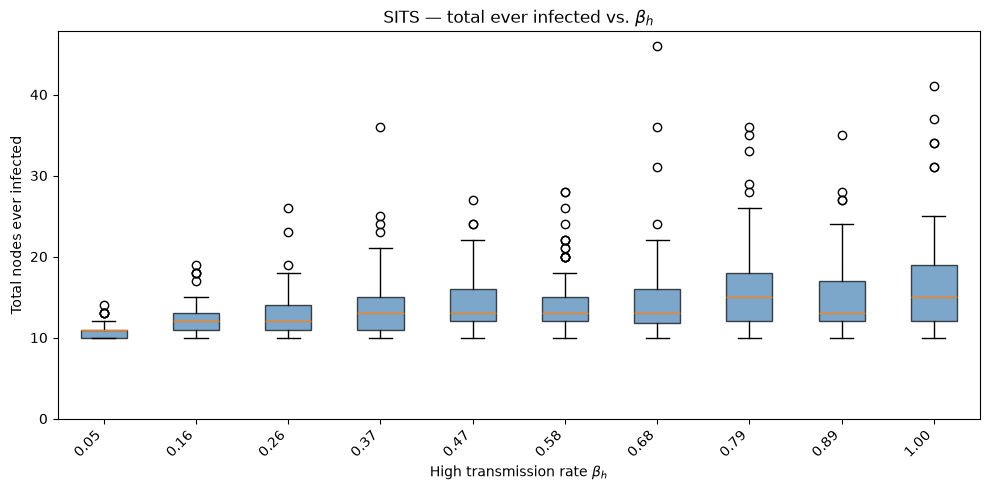

In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    [ever_infected_beta_h[bh] for bh in beta_high_values],
    label=[f'{bh:.2f}' for bh in beta_high_values],
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', alpha=0.7)
)
ax.set_xticklabels([f'{bh:.2f}' for bh in beta_high_values], rotation=45, ha='right')
ax.set_ylim(bottom=0)
ax.set_xlabel(r'High transmission rate $\beta_h$')
ax.set_ylabel('Total nodes ever infected')
ax.set_title(r'SITS — total ever infected vs. $\beta_h$')
plt.tight_layout()
plt.show()


<a id="stis-p"></a>
## Outbreak size as a function of testing probability

In [19]:
OUTBREAK_THRESHOLD = 50   # a run is an outbreak if more than this many nodes were ever infected

p_values = np.linspace(0, 1, 10)
summary_by_p = {}

beta_map_p = sim.assign_transmission_rates_generic(agg_degree_map, criterion='random')

for p in p_values:
    counts, _ = sim.run_SITS_simulations_generic(
        edges_by_snapshot, all_nodes, beta_map_p,
        n_simulations=N_SIMULATIONS, n_seeds=10, p_test=p
    )
    summary_by_p[p] = sim.summarize_epidemic(counts, outbreak_threshold=OUTBREAK_THRESHOLD)


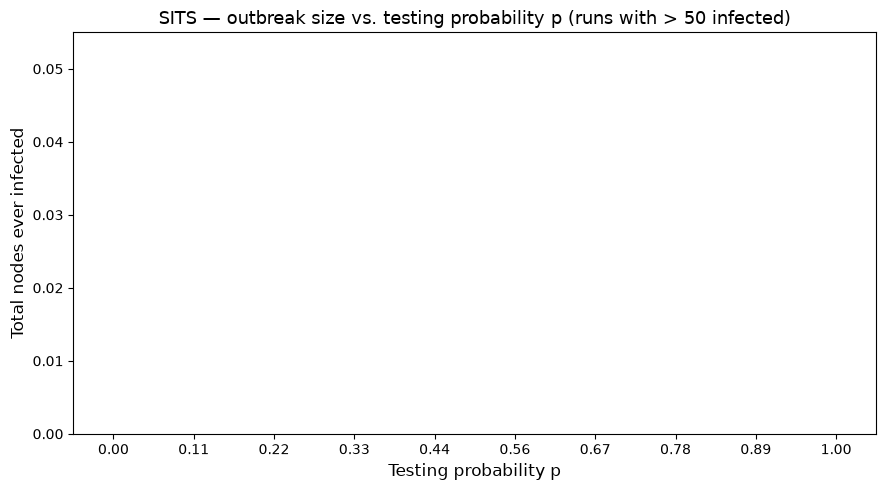

In [20]:
# Outbreak size: total ever infected, outbreak runs only
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    [summary_by_p[p]['ever'][summary_by_p[p]['outbreak']] for p in p_values],
    label=[f'{p:.2f}' for p in p_values],
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', alpha=0.6),
    medianprops=dict(color='black', linewidth=2),
    whiskerprops=dict(linewidth=1.2),
    capprops=dict(linewidth=1.2),
    flierprops=dict(marker='o', markersize=3, alpha=0.5)
)
ax.set_xticklabels([f'{p:.2f}' for p in p_values])
ax.set_ylim(bottom=0)
ax.set_xlabel('Testing probability p', fontsize=12)
ax.set_ylabel('Total nodes ever infected', fontsize=12)
ax.set_title(f'SITS — outbreak size vs. testing probability p (runs with > {OUTBREAK_THRESHOLD} infected)', fontsize=13)
ax.set_box_aspect(0.5)
plt.tight_layout()
plt.show()


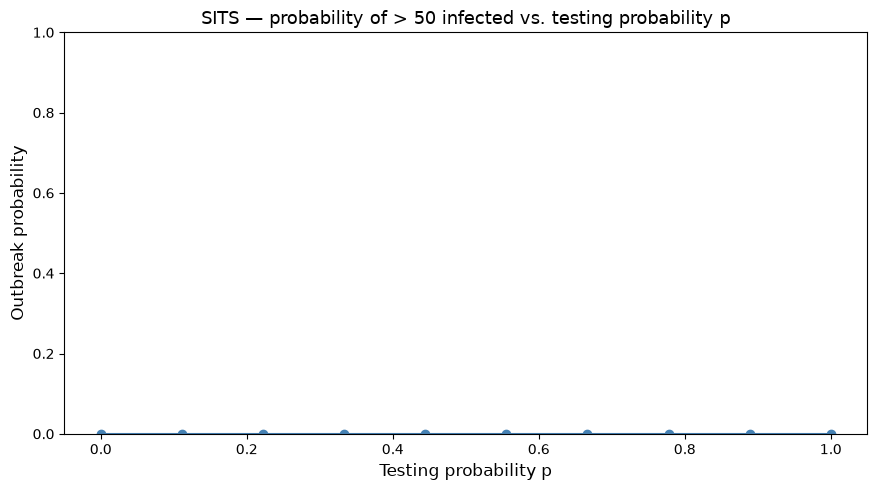

In [21]:
# Outbreak probability vs. testing probability
p_out = np.array([summary_by_p[p]['p_outbreak'] for p in p_values])
err   = np.sqrt(p_out * (1 - p_out) / N_SIMULATIONS)   # binomial standard error

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(p_values, p_out, yerr=err, color='steelblue', marker='o', capsize=3, linewidth=1.5)
ax.set_ylim(0, 1)
ax.set_xlabel('Testing probability p', fontsize=12)
ax.set_ylabel('Outbreak probability', fontsize=12)
ax.set_title(f'SITS — probability of > {OUTBREAK_THRESHOLD} infected vs. testing probability p', fontsize=13)
ax.set_box_aspect(0.5)
plt.tight_layout()
plt.show()


<a id="stis-tt"></a>
## $STIS(T_t)$: outbreak size as function of the testing time 
Compared to the previous STIS the nodes get tested at uniforms time intervals.

In [22]:
# Periodic-testing model: run for T_t = 6, 12, 24 months
T_t_values = [6, 12, 24]
sitp_results = {}

beta_map_sitp = sim.assign_transmission_rates_generic(
    agg_degree_map, criterion='random'
)

for T_t in T_t_values:
    counts, snaps = sim.run_SITp_simulations_generic(
        edges_by_snapshot, all_nodes, beta_map_sitp,
        n_simulations=N_SIMULATIONS, n_seeds=10, T_t=T_t,
    )
    sitp_results[T_t] = (counts, snaps)


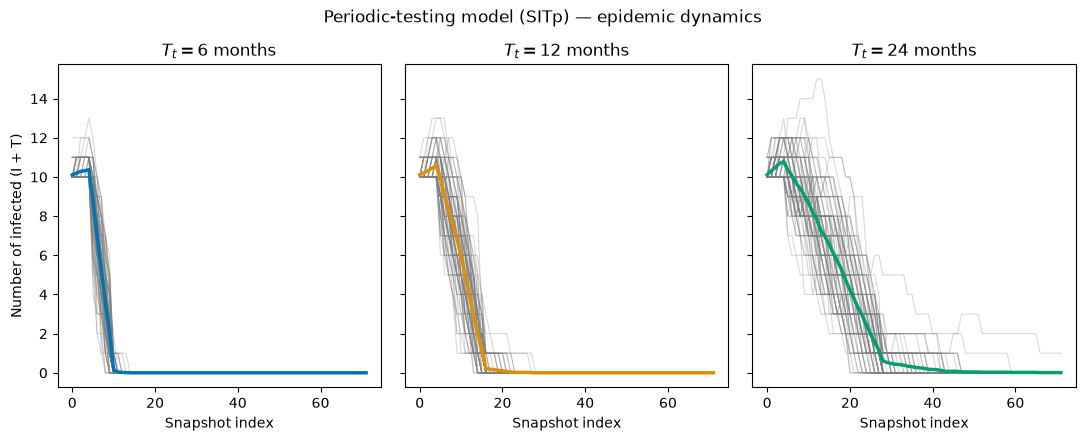

In [23]:
pal = sns.color_palette('colorblind', 6)
T_t_colors = {6: pal[0], 12: pal[1], 24: pal[2]}
T_t_labels = {6: r'$T_t = 6$ months', 12: r'$T_t = 12$ months', 24: r'$T_t = 24$ months'}

fig, axes = plt.subplots(1, 3, figsize=(11, 4), sharex=True, sharey=True)

for ax, T_t in zip(axes, T_t_values):
    counts, snaps = sitp_results[T_t]
    x = np.arange(len(snaps))   # snaps are (year, month) tuples; use integer index for x-axis
    total = counts['I'] + counts['T']
    for traj in total:
        ax.plot(x, traj, color='gray', linewidth=0.8, alpha=0.3)
    ax.plot(x, total.mean(axis=0), color=T_t_colors[T_t], linewidth=2.5,
            label=T_t_labels[T_t])
    ax.set_title(T_t_labels[T_t])
    ax.set_xlabel('Snapshot index')
    ax.set_box_aspect(1)

axes[0].set_ylabel('Number of infected (I + T)')
fig.suptitle('Periodic-testing model (SITp) — epidemic dynamics', y=1.02)
fig.tight_layout()
plt.show()


In [24]:
# Sweep T_t from 6 to 24 months (15 points)
T_t_sweep = [int(round(v)) for v in np.linspace(6, 24, 15)]
summary_by_T_t = {}

beta_map_sweep = sim.assign_transmission_rates_generic(
    agg_degree_map, criterion='random'
)

for T_t in T_t_sweep:
    counts, _ = sim.run_SITp_simulations_generic(
        edges_by_snapshot, all_nodes, beta_map_sweep,
        n_simulations=N_SIMULATIONS, n_seeds=10, T_t=T_t,
    )
    summary_by_T_t[T_t] = sim.summarize_epidemic(counts, outbreak_threshold=OUTBREAK_THRESHOLD)


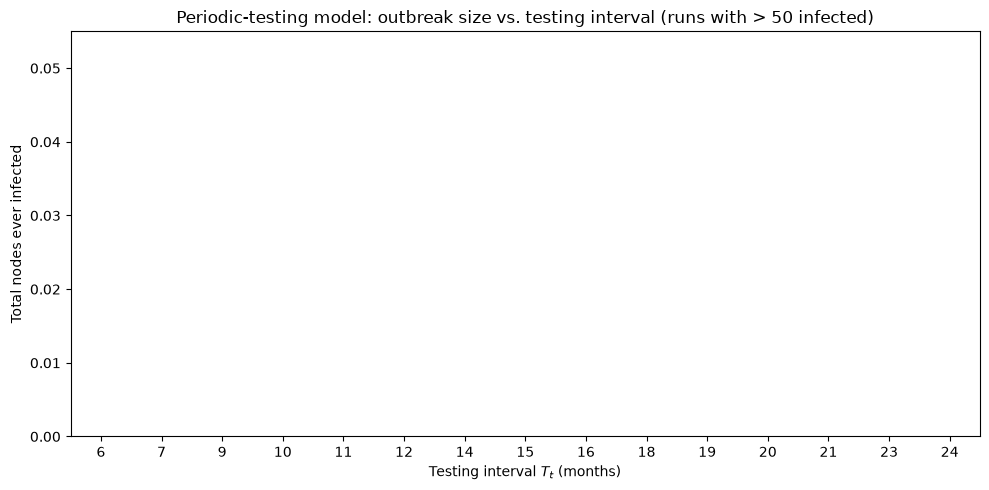

In [25]:
# Outbreak size: total ever infected, outbreak runs only
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    [summary_by_T_t[T_t]['ever'][summary_by_T_t[T_t]['outbreak']] for T_t in T_t_sweep],
    label=T_t_sweep,
    patch_artist=True,
    boxprops=dict(facecolor='steelblue', alpha=0.7)
)
ax.set_xticklabels(T_t_sweep)
ax.set_ylim(bottom=0)
ax.set_xlabel('Testing interval $T_t$ (months)')
ax.set_ylabel('Total nodes ever infected')
ax.set_title(f'Periodic-testing model: outbreak size vs. testing interval (runs with > {OUTBREAK_THRESHOLD} infected)')
plt.tight_layout()
plt.show()


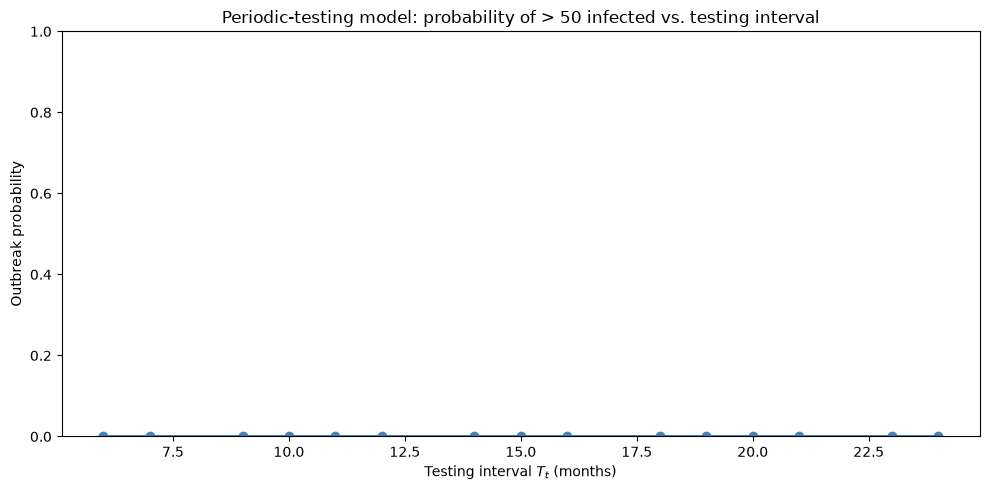

In [26]:
# Outbreak probability vs. testing interval
p_out = np.array([summary_by_T_t[T_t]['p_outbreak'] for T_t in T_t_sweep])
err   = np.sqrt(p_out * (1 - p_out) / N_SIMULATIONS)   # binomial standard error

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(T_t_sweep, p_out, yerr=err, color='steelblue', marker='o', capsize=3, linewidth=1.5)
ax.set_ylim(0, 1)
ax.set_xlabel('Testing interval $T_t$ (months)')
ax.set_ylabel('Outbreak probability')
ax.set_title(f'Periodic-testing model: probability of > {OUTBREAK_THRESHOLD} infected vs. testing interval')
plt.tight_layout()
plt.show()
